(sec-7)=
# 7. Dashboard y despliegue

(sec-7-1)=
## 7.1 Artefacto del modelo original y prueba de ida y vuelta

El dashboard nunca entrena modelos (guía, sección 4.2): carga artefactos ya ajustados. El L2E se serializa con `joblib` (compresión 3) en dos versiones: `modelo.joblib`, con el estado al cierre del entrenamiento, que es el que se evaluó en la prueba, y `modelo_vigente.joblib`, que además asimiló con `actualizar` las etiquetas de todos los días de la prueba y es el que el dashboard debe usar para predecir un día nuevo. Junto a ellos, `metadata.json` registra las versiones de las librerías, la semilla, los hiperparámetros, el esquema de entrada y las métricas del bucle externo y de la prueba. La prueba de ida y vuelta verifica que el modelo leído de disco produce exactamente las mismas predicciones que el modelo en memoria. Estos artefactos referencian el paquete de investigación `bm`; la versión que carga el dashboard la genera `scripts/exportar_dashboard_l2e.py` con la copia de producción de la clase y repite la misma verificación (sección {ref}`7.3 <sec-7-3>`).

In [29]:
import copy
import joblib

DEST = Path("artifacts") / "l2e"
DEST.mkdir(parents=True, exist_ok=True)
pipe = L2E["pipeline"]
X_te_d = con_dia(X_te, tiempo_te)
joblib.dump(pipe, DEST / "modelo.joblib", compress=3)
vigente = copy.deepcopy(pipe)
vigente[-1].actualizar(vigente[:-1].transform(X_te_d), yte)
joblib.dump(vigente, DEST / "modelo_vigente.joblib", compress=3)

esquema = {}
for c in X_tr.columns:
    if c in cfg.VARS_NUM:
        esquema[c] = {"tipo": "numérica", "min": float(X_tr[c].min()), "max": float(X_tr[c].max())}
    elif c in cfg.VARS_CAT:
        esquema[c] = {"tipo": "categórica", "valores": sorted(map(str, X_tr[c].unique()))}
esquema["dia"] = {"tipo": "entero", "descripcion": "día de contacto reconstruido (bm.datos.reconstruir_tiempo)"}
metadata = {
    "modelo": "LogisticaDosEscalas (L2E)", "clase": "bm.modelo_original.LogisticaDosEscalas", "semilla": SEED,
    "versiones": {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
                  "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
    "hiperparametros": {k.split("__")[1]: float(v) for k, v in L2E["params"].items()},
    "parametros_fijos": {"retardo": 1, "nivel_latente": True, "actualizar_nivel": True, "actualizar_pendientes": True,
                         "integrar_incertidumbre": True},
    "esquema_entrada": esquema,
    "metricas_bucle_externo": {"auc_pr_media": float(ext["L2E"].mean()), "auc_pr_de": float(ext["L2E"].std(ddof=1)),
                               "auc_media": float(np.mean(ext_auc["L2E"]))},
    "metricas_prueba": {"auc_pr": float(ap_te["L2E"]), "auc": float(auc_te["L2E"]),
                        "brier": float(brier_score_loss(yte, PUNTAJE_TE["L2E"]))},
    "estado": {"modelo.joblib": {"ultimo_dia": int(pipe[-1].dia_final_), "periodo": str(periodo_tr.iloc[-1])},
               "modelo_vigente.joblib": {"ultimo_dia": int(vigente[-1].dia_final_), "periodo": str(periodo_te.iloc[-1])}},
}
(DEST / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=1), encoding="utf-8")

leido = joblib.load(DEST / "modelo.joblib")
s_leido = puntaje_secuencial(leido, X_te_d, y_te)
dif_script = float(np.max(np.abs(s_leido - L2E["puntaje_te"])))
ida_vuelta = pd.DataFrame([
    {"Verificación": "predict_proba (estático): memoria frente a disco", "Criterio": "igualdad exacta",
     "Resultado": "idénticas" if np.array_equal(leido.predict_proba(X_te_d), pipe.predict_proba(X_te_d)) else "DIFERENTES"},
    {"Verificación": "predict_proba_secuencial: memoria frente a disco", "Criterio": "igualdad exacta",
     "Resultado": "idénticas" if np.array_equal(s_leido, puntaje_secuencial(pipe, X_te_d, y_te)) else "DIFERENTES"},
    {"Verificación": "frente al puntaje evaluado en la prueba (otro proceso)", "Criterio": "diferencia máxima < 1e−10",
     "Resultado": f"diferencia máxima {dif_script:.1e}" + (" (coinciden)" if dif_script < 1e-10 else " (DIFERENTES)")}])
tamanos = {f.name: f.stat().st_size / 1024 for f in DEST.iterdir()}
tabla(ida_vuelta, indice=False)
tabla(pd.Series(tamanos, name="Tamaño (KB)").to_frame(), dec=1)
assert ida_vuelta["Resultado"].iloc[:2].eq("idénticas").all() and dif_script < 1e-10
print("La comparación con el puntaje de la prueba se hace con tolerancia porque ese puntaje se calculó en otro proceso, "
      "con BLAS de un solo hilo; el orden de las sumas de punto flotante cambia en el último dígito.")

Verificación,Criterio,Resultado
predict_proba (estático): memoria frente a disco,igualdad exacta,idénticas
predict_proba_secuencial: memoria frente a disco,igualdad exacta,idénticas
frente al puntaje evaluado en la prueba (otro proceso),diferencia máxima < 1e−10,diferencia máxima 4.4e-16 (coinciden)


,Tamaño (KB)
metadata.json,"3,2"
modelo.joblib,"18,2"
modelo_vigente.joblib,"18,6"


La comparación con el puntaje de la prueba se hace con tolerancia porque ese puntaje se calculó en otro proceso, con BLAS de un solo hilo; el orden de las sumas de punto flotante cambia en el último dígito.


(sec-7-2)=
## 7.2 Predicción en vivo con explicación local

Así se usa el modelo en el dashboard: se toma un cliente con sus variables previas a la llamada, se le asigna el día siguiente al último asimilado y el modelo vigente devuelve la probabilidad y su descomposición exacta en el logit: el nivel del día y la contribución de cada variable del cliente.

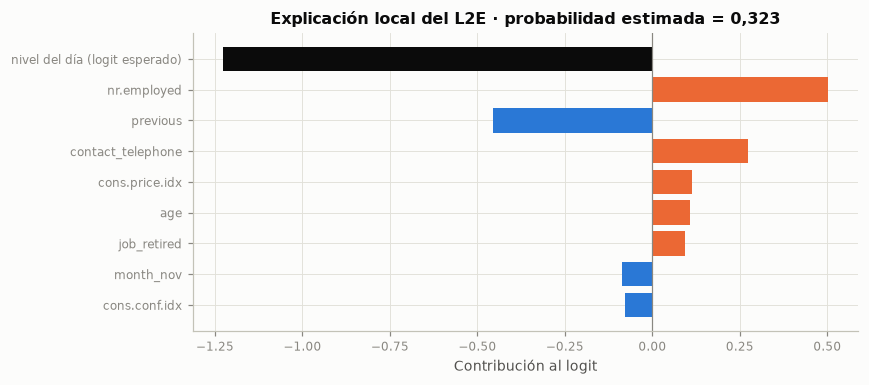

,Valor
age,74
campaign,3
pdays,999
previous,1
cons.price.idx,"94,767"
cons.conf.idx,"-50,800"
nr.employed,"4 963,600"
job,retired
marital,married
education,professional.course


**Interpretación.** Para este cliente, con el estado vigente al cierre de 2010-11, el L2E estima una probabilidad de suscripción de 0,323. El nivel del día aporta -1,23 al logit y la variable con mayor contribución es `nr.employed` (0,50).

De esta forma, la explicación local separa lo que se debe al momento (el nivel del día, común a todos los clientes que se llamen ese día) de lo que se debe al cliente, y responde a la pregunta que se hace un asesor: si conviene llamarlo hoy y por qué.

Por tanto, corresponde incorporar esta salida, la trayectoria del nivel y la tabla de pruebas de la sección {ref}`6.7 <sec-6-7>` a la subsección del modelo original de la página Modelos del dashboard (sección {ref}`7.3 <sec-7-3>`).

In [30]:
cliente = X_te.iloc[[-1]].copy()
dia_nuevo = int(vigente[-1].dia_final_) + 1
fila = cliente.assign(dia=dia_nuevo)
prob = float(vigente.predict_proba(fila)[0, 1])
Z = vigente[:-1].transform(fila)[:, :-1]
m_v = vigente[-1].estado_media_
xbar = vigente[:-1].transform(con_dia(X_tr, tiempo_tr))[:, :-1].mean(axis=0)
contrib = pd.Series(m_v[1:] * (Z[0] - xbar), index=nombres)
nivel_dia = float(m_v[0] + m_v[1:] @ xbar)
top_c = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:8])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(["nivel del día (logit esperado)"] + list(top_c.index), [nivel_dia] + list(top_c.values),
        color=[TINTA] + [NARANJA if v > 0 else AZUL for v in top_c.values])
ax.axvline(0, color=GRIS, lw=0.8)
ax.invert_yaxis()
ax.set(title=f"Explicación local del L2E · probabilidad estimada = {num(prob, 3)}", xlabel="Contribución al logit")
plt.tight_layout()
plt.show()
tabla(cliente[cfg.VARS_NUM + cfg.VARS_CAT].T.rename(columns={cliente.index[0]: "Valor"}), indice=True)
interpretar(
    f"Para este cliente, con el estado vigente al cierre de {periodo_te.iloc[-1]}, el L2E estima una probabilidad de "
    f"suscripción de {num(prob, 3)}. El nivel del día aporta {num(nivel_dia, 2)} al logit y la variable con mayor "
    f"contribución es `{top_c.index[0]}` ({num(top_c.iloc[0], 2)}).",
    conectar("De esta forma,", "La explicación local separa lo que se debe al momento (el nivel del día, común a todos "
             "los clientes que se llamen ese día) de lo que se debe al cliente, y responde a la pregunta que se hace un "
             "asesor: si conviene llamarlo hoy y por qué."),
    conectar("Por tanto, corresponde", "Incorporar esta salida, la trayectoria del nivel y la tabla de pruebas de la "
             "sección 6.7 a la subsección del modelo original de la página Modelos del dashboard (sección 7.3)."))

(sec-7-3)=
## 7.3 Dashboard desplegado: arquitectura, decisiones de diseño y despliegue

El dashboard está en línea en Render: **<https://proyecto-final-bank-marketing.onrender.com>**. Tiene las tres páginas que pide la guía (Contexto, EDA y Modelos) y, desde este entregable, el L2E es un modelo más del dashboard: encabeza la tabla de líderes, se puede elegir en la predicción en vivo, tiene su diagnóstico y su SHAP global, entra al diagrama de diferencia crítica y cuenta con su propia subsección.

**Arquitectura.** El repositorio (<https://github.com/DTL-DA/proyecto-final-bank-marketing>) sigue la estructura de la sección 7.2 de la guía; este cuaderno y su código de investigación están en `cuarto_entregable/`:

```text
proyecto-final-bank-marketing/
├── app.py                  punto de entrada: crea la aplicación multipágina y expone server (gunicorn)
├── pages/                  contexto.py, eda.py y modelos.py (una página por sección, con sus callbacks)
├── src/
│   ├── original_model.py   clase del modelo original (copia de producción de bm.modelo_original)
│   ├── data.py             carga y caché de datos, artefactos y resultados precalculados
│   ├── plots.py            funciones que construyen las figuras, con una plantilla común de Plotly
│   ├── explicaciones.py    valores SHAP por permutaciones (sin cargar la librería shap en el servidor)
│   └── componentes.py      componentes propios de los pipelines de los benchmarks
├── artifacts/              un directorio por modelo con modelo.joblib y metadata.json (l2e incluido)
├── data/                   datos livianos para el EDA y resultados precalculados (data/resultados)
├── assets/                 hoja de estilos
├── tests/                  pruebas con pytest: aplicación, artefactos, explicaciones y modelo original
├── book/                   fuentes del Jupyter Book (_config.yml, _toc.yml, references.bib)
├── cuarto_entregable/      este cuaderno, src/bm, scripts, pruebas y resultados del modelo original
├── requirements.txt        versiones exactas
└── render.yaml             configuración del despliegue
```

**Integración del modelo original.** `scripts/exportar_dashboard_l2e.py` toma el modelo final de la sección {ref}`7.1 <sec-7-1>`, reemplaza las referencias al paquete de investigación `bm` por la copia de producción `src/original_model.py` (el algoritmo es idéntico línea por línea, y `tests/test_original_model.py` lo verifica junto con las 25 pruebas unitarias del modelo), repite la prueba de ida y vuelta, guarda los dos artefactos en `artifacts/l2e/` y agrega el L2E a las tablas precalculadas del dashboard. Como el dashboard nunca entrena ni optimiza, todo lo que muestra sale de esos artefactos y de esas tablas. Para predecir, el dashboard carga `modelo_vigente.joblib` y le asigna al cliente el día siguiente al último cerrado (sección {ref}`7.2 <sec-7-2>`).

**Decisiones de diseño.**

- *Un producto, no una colección de gráficos:* cada tarjeta responde una pregunta del usuario (a quién llamar primero, qué tan confiable es la probabilidad, qué modelo es mejor y por qué) y termina con una frase de interpretación.
- *Tema y color:* `dash-bootstrap-components` con el tema FLATLY, barra de navegación fija y una paleta de dos colores más grises, validada para visión normal y para las tres formas de daltonismo. El color sigue a la entidad: el L2E es siempre naranja y los benchmarks, azules, y la identidad nunca depende solo del color, porque cada serie tiene su etiqueta.
- *Rendimiento en el plan gratuito:* los datos y los ocho modelos se cargan una sola vez con `functools.lru_cache`; los valores SHAP se estiman con un estimador por permutaciones propio, porque la librería `shap` no cabe en la memoria junto con los modelos, y el L2E solo suma 37 KB de artefactos.
- *Robustez y accesibilidad:* el formulario de predicción se genera desde el esquema de variables y valida tipos y rangos; un error se informa con `dbc.Alert` sin detener la aplicación. Las tablas y las figuras usan la rejilla de `dbc.Row` y `dbc.Col` para escritorio y tableta, con etiquetas descriptivas y contraste suficiente.

**Guía de despliegue.** (1) `python app.py` levanta el dashboard en local en <http://127.0.0.1:8050>. (2) `requirements.txt` fija las versiones exactas, incluido `gunicorn`, y `render.yaml` fija Python 3.12.10. (3) Render construye con `pip install -r requirements.txt` y arranca con `gunicorn app:server --workers 1 --threads 4 --timeout 120`; cada *push* a la rama `main` del repositorio dispara un despliegue nuevo. (4) Después de cada despliegue se revisan los registros de construcción y se recorren las tres páginas en la URL pública. En el plan gratuito el servicio se suspende tras 15 minutos sin visitas y la primera carga tarda cerca de un minuto, por lo que conviene abrirlo unos minutos antes de la sustentación.

**Capturas.** Las capturas se tomaron con `scripts/capturas_dashboard.py` sobre el dashboard local, con los mismos artefactos y datos que la versión en línea.

![Página Contexto del dashboard: problema, pregunta de investigación, datos, metodología y limitaciones](imagenes/dashboard_contexto.png)

![Página EDA del dashboard: filtros globales, distribución del objetivo, explorador bivariado, correlación, faltantes y atípicos](imagenes/dashboard_eda.png)

![Página Modelos, primera parte: tabla de líderes con el L2E, predicción en vivo con su explicación SHAP local y diagnóstico del modelo seleccionado](imagenes/dashboard_modelos_1.png)

![Página Modelos, segunda parte: SHAP global, diagrama de diferencia crítica con el modelo original y subsección del L2E con su veredicto](imagenes/dashboard_modelos_2.png)